In [3]:
import os
import numpy as np, pandas as pd
import seaborn as sns, matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")
np.random.seed(42)
os.makedirs("../report/figures", exist_ok=True)
def save(name): plt.savefig(f"../report/figures/{name}.png", dpi=150, bbox_inches="tight")

df = fetch_california_housing(as_frame=True).frame
print(df.shape); df.info(); print(df.describe().T)
print("Missing:", df.isna().sum().sum(), "| Duplicates:", df.duplicated().sum())

(20640, 9)
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
               count         mean          std         min         25%  \
MedInc       20640.0     3.870671     1.899822    0.499900    2.563400   
HouseAge     20640.0    28.639486    12.585558    1.000000   18.000000   
AveRooms     20640.0     5.429000     2.474173    0.846154    4.440716   
AveBedrms    20640.0     1.096675     0.473911    0.333333    1.006079   
Population   20640.0

In [4]:
print("Target at cap 5.0:", (df["MedHouseVal"] >= 5).sum())
print("HouseAge at 52:", (df["HouseAge"] == 52).sum())
print(df[["AveRooms", "AveBedrms", "AveOccup", "Population"]].describe(percentiles=[.99, .999]).T)

n0 = len(df)
df = df[df["MedHouseVal"] < 5]          # target is censored at 5.0 (values above are not observed)
df = df[(df["AveOccup"] < 10) & (df["AveRooms"] < 20)]   # implausible averages (e.g. AveOccup up to 1,243)
print("Rows removed:", n0 - len(df), "| remaining:", len(df))

Target at cap 5.0: 992
HouseAge at 52: 1273
              count         mean          std       min          99%  \
AveRooms    20640.0     5.429000     2.474173  0.846154    10.357033   
AveBedrms   20640.0     1.096675     0.473911  0.333333     2.127541   
AveOccup    20640.0     3.070655    10.386050  0.692308     5.394812   
Population  20640.0  1425.476744  1132.462122  3.000000  5805.830000   

                   99.9%           max  
AveRooms       34.199698    141.909091  
AveBedrms       6.617232     34.066667  
AveOccup       13.630443   1243.333333  
Population  10372.681000  35682.000000  
Rows removed: 1092 | remaining: 19548


In [5]:
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

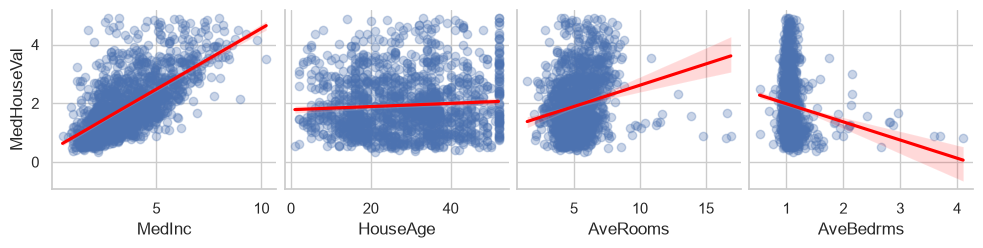

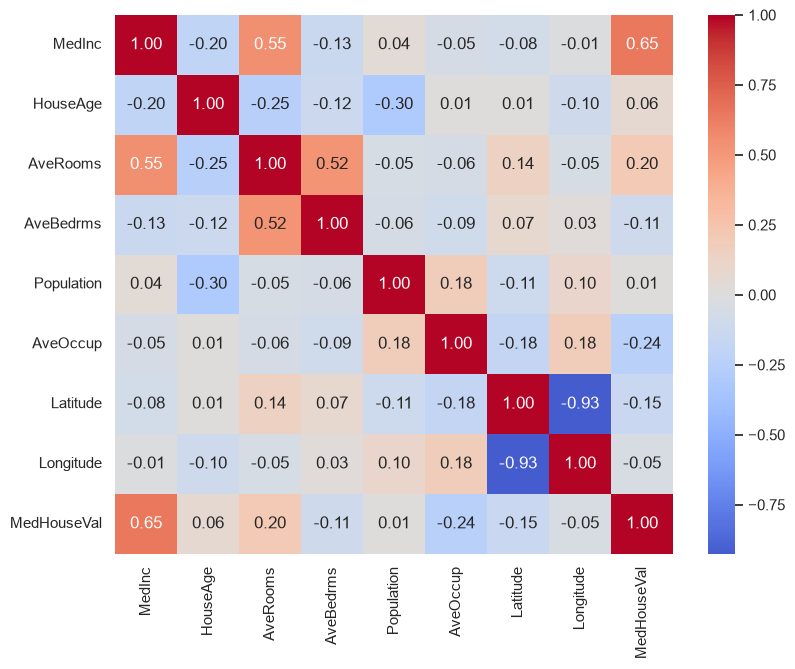

Latitude      10.00
Longitude      9.47
AveRooms       3.59
MedInc         2.83
AveBedrms      2.16
HouseAge       1.30
Population     1.17
AveOccup       1.09
dtype: float64


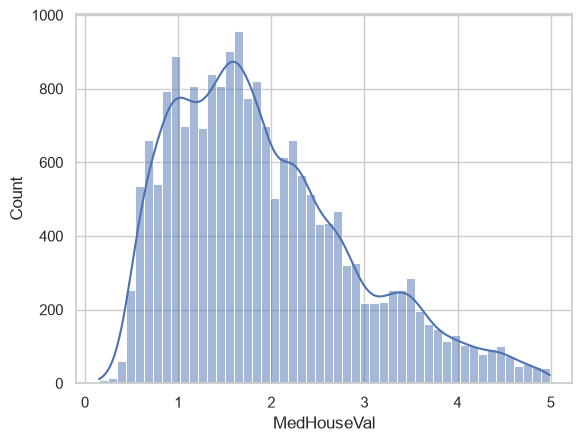

Skewness: 0.7926437697801557


In [6]:
# Linearity and relationships
sns.pairplot(df.sample(1500, random_state=42), y_vars="MedHouseVal", x_vars=X.columns[:4], kind="reg",
             plot_kws={"scatter_kws": {"alpha": .3}, "line_kws": {"color": "red"}})
save("linearity_check"); plt.show()

plt.figure(figsize=(9, 7)); sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
save("heatmap"); plt.show()

# Multicollinearity: VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor
Xc = sm.add_constant(X_train)
vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(Xc.shape[1])], index=Xc.columns).drop("const")
print(vif.sort_values(ascending=False).round(2))

# Target distribution (normality of the outcome, a first look)
sns.histplot(y, kde=True); save("target_hist"); plt.show()
print("Skewness:", y.skew())

In [7]:
Xtr = sm.add_constant(X_train)
m1 = sm.OLS(y_train, Xtr).fit()
print(m1.summary())
print(m1.conf_int().round(3))

                            OLS Regression Results                            
Dep. Variable:            MedHouseVal   R-squared:                       0.625
Model:                            OLS   Adj. R-squared:                  0.624
Method:                 Least Squares   F-statistic:                     3251.
Date:                Mon, 23 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:47:04   Log-Likelihood:                -14015.
No. Observations:               15638   AIC:                         2.805e+04
Df Residuals:                   15629   BIC:                         2.812e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -31.9210      0.640    -49.860      0.0

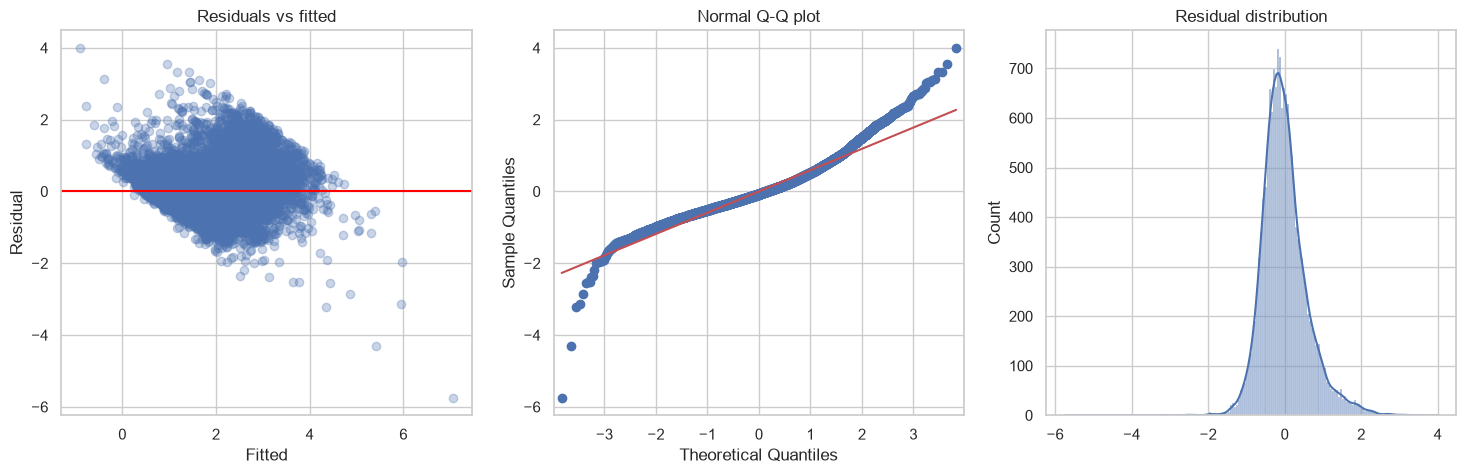

Breusch-Pagan p: 5.017420776667774e-137
Jarque-Bera p: 0.0
Durbin-Watson: 1.9707525933181367
Influential points (Cook's D > 4/n): 909


In [8]:
resid, fitted = m1.resid, m1.fittedvalues

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].scatter(fitted, resid, alpha=.3); ax[0].axhline(0, color="red"); ax[0].set(title="Residuals vs fitted", xlabel="Fitted", ylabel="Residual")
sm.qqplot(resid, line="s", ax=ax[1]); ax[1].set_title("Normal Q-Q plot")
sns.histplot(resid, kde=True, ax=ax[2]); ax[2].set_title("Residual distribution")
save("diagnostics_baseline"); plt.show()

from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson, jarque_bera
print("Breusch-Pagan p:", het_breuschpagan(resid, Xtr)[1])
print("Jarque-Bera p:", jarque_bera(resid)[1])
print("Durbin-Watson:", durbin_watson(resid))

cooks = m1.get_influence().cooks_distance[0]
print("Influential points (Cook's D > 4/n):", (cooks > 4/len(Xtr)).sum())

In [9]:
def prep(Xdf):
    Z = Xdf.drop(columns="AveBedrms").copy()       # collinear with AveRooms
    Z["Population"] = np.log(Z["Population"])      # skewed
    return sm.add_constant(Z)

Xtr2, Xte2 = prep(X_train), prep(X_test)
m2 = sm.OLS(np.log(y_train), Xtr2).fit(cov_type="HC3")   # log target + heteroscedasticity-robust SEs
print(m2.summary())

                            OLS Regression Results                            
Dep. Variable:            MedHouseVal   R-squared:                       0.642
Model:                            OLS   Adj. R-squared:                  0.642
Method:                 Least Squares   F-statistic:                     2989.
Date:                Mon, 23 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:47:22   Log-Likelihood:                -4247.7
No. Observations:               15638   AIC:                             8511.
Df Residuals:                   15630   BIC:                             8573.
Df Model:                           7                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -21.7684      0.407    -53.432      0.0

                   model   RMSE    MAE     R2
0           Baseline OLS  0.596  0.441  0.636
1  Improved (log target)  0.607  0.423  0.622
Train R2 (baseline): 0.625 | Train adj R2: 0.624
AIC baseline: 28048.812913910428 | AIC improved: 8511.450263814939


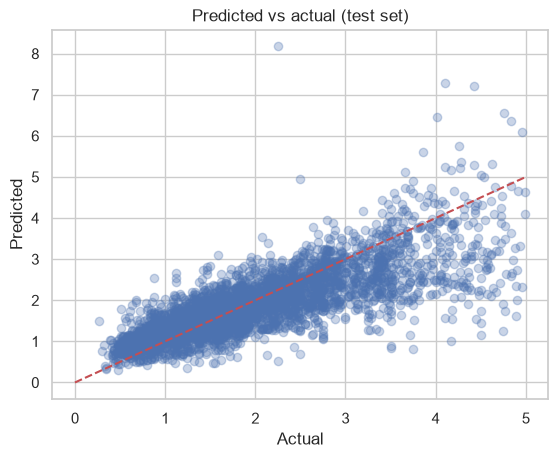

In [10]:
pred1 = m1.predict(sm.add_constant(X_test))
pred2 = np.exp(m2.predict(Xte2))                      # back-transform to original units

def scores(name, yt, yp):
    return {"model": name, "RMSE": np.sqrt(mean_squared_error(yt, yp)),
            "MAE": mean_absolute_error(yt, yp), "R2": r2_score(yt, yp)}

res = pd.DataFrame([scores("Baseline OLS", y_test, pred1), scores("Improved (log target)", y_test, pred2)])
print(res.round(3))
print("Train R2 (baseline):", round(m1.rsquared, 3), "| Train adj R2:", round(m1.rsquared_adj, 3))
print("AIC baseline:", m1.aic, "| AIC improved:", m2.aic)   # not comparable across log/non-log targets, see note

plt.scatter(y_test, pred2, alpha=.3); plt.plot([0, 5], [0, 5], "r--")
plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.title("Predicted vs actual (test set)")
save("pred_vs_actual"); plt.show()

In [11]:
coef = m2.summary2().tables[1][["Coef.", "Std.Err.", "P>|z|", "[0.025", "0.975]"]]
print(coef.round(4))

              Coef.  Std.Err.   P>|z|   [0.025   0.975]
const      -21.7684    0.4074  0.0000 -22.5669 -20.9699
MedInc       0.1898    0.0031  0.0000   0.1838   0.1958
HouseAge     0.0030    0.0003  0.0000   0.0025   0.0035
AveRooms    -0.0083    0.0037  0.0263  -0.0156  -0.0010
Population   0.0453    0.0055  0.0000   0.0346   0.0561
AveOccup    -0.1549    0.0048  0.0000  -0.1644  -0.1454
Latitude    -0.2710    0.0045  0.0000  -0.2798  -0.2621
Longitude   -0.2622    0.0047  0.0000  -0.2713  -0.2530


In [12]:
df["high_value"] = (df["MedHouseVal"] > df["MedHouseVal"].median()).astype(int)
Xl = sm.add_constant(prep(df.drop(columns=["MedHouseVal", "high_value"])))
logit = sm.Logit(df["high_value"], Xl).fit()
print(logit.summary()); print(np.exp(logit.params).round(3))   # odds ratios

Optimization terminated successfully.
         Current function value: 0.377285
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:             high_value   No. Observations:                19548
Model:                          Logit   Df Residuals:                    19540
Method:                           MLE   Df Model:                            7
Date:                Mon, 23 Nov 2026   Pseudo R-squ.:                  0.4557
Time:                        19:48:11   Log-Likelihood:                -7375.2
converged:                       True   LL-Null:                       -13550.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       -147.7511      3.582    -41.249      0.000    -154.772    -140.731
MedInc         1.2269      0.

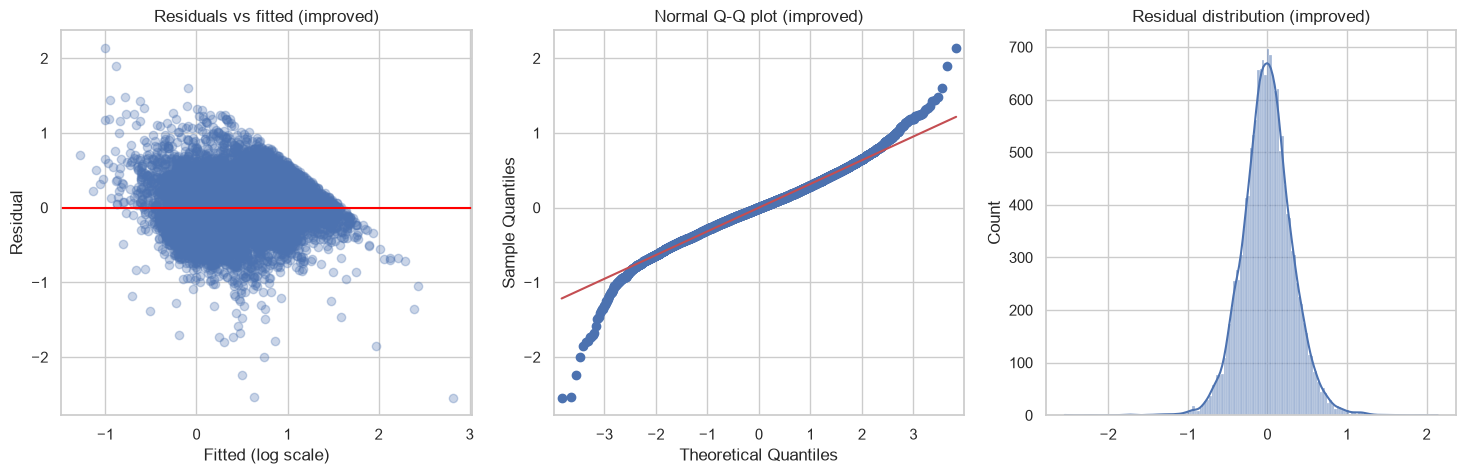

IMPROVED R2: 0.642 | ADJ R2: 0.642
                model  RMSE   MAE    R2
         Baseline OLS 0.596 0.441 0.636
Improved (log target) 0.607 0.423 0.622
Breusch-Pagan baseline: LM=658.9, p=5.02e-137
Breusch-Pagan improved: LM=845.0, p=3.60e-178
Jarque-Bera p (improved): 0.0


In [13]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import jarque_bera

# 1) Create the missing figure: report/figures/diagnostics_improved.png
resid2, fitted2 = m2.resid, m2.fittedvalues
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].scatter(fitted2, resid2, alpha=.3); ax[0].axhline(0, color="red")
ax[0].set(title="Residuals vs fitted (improved)", xlabel="Fitted (log scale)", ylabel="Residual")
sm.qqplot(resid2, line="s", ax=ax[1]); ax[1].set_title("Normal Q-Q plot (improved)")
sns.histplot(resid2, kde=True, ax=ax[2]); ax[2].set_title("Residual distribution (improved)")
save("diagnostics_improved"); plt.show()

# 2) Print every value the report is missing
print("IMPROVED R2:", round(m2.rsquared, 3), "| ADJ R2:", round(m2.rsquared_adj, 3))
print(res.round(3).to_string(index=False))          # test RMSE, MAE, R2 for both models
bp1 = het_breuschpagan(m1.resid, Xtr)
bp2 = het_breuschpagan(m2.resid, Xtr2)
print(f"Breusch-Pagan baseline: LM={bp1[0]:.1f}, p={bp1[1]:.2e}")
print(f"Breusch-Pagan improved: LM={bp2[0]:.1f}, p={bp2[1]:.2e}")
print("Jarque-Bera p (improved):", jarque_bera(resid2)[1])